Isaac Noe

10/23/2026

Checkpoint 2 — Engine Demo

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lab07_engine as engine

Body = engine.Body
Gravity = engine.Gravity
Spring = engine.Spring
Verlet = engine.Verlet
World = engine.World

In [2]:
# Setup
dt = 0.001
duration = 5.0
bounds = (-2.0, 2.0, -2.0, 2.0)
radius = 0.16
world = World(Verlet())

bodies = [Body(1.0, [-1.25,  0.90], [ 1.70, -0.10], radius),
    Body(1.0, [ 0.10,  0.90], [-0.10,  0.00], radius),
    Body(1.2, [-0.90, -0.90], [ 1.10,  0.10], radius),
    Body(1.2, [ 0.10, -0.90], [ 0.00,  0.00], radius)]
for body in bodies:
    world.add_body(body)

gravity = Gravity(g=1.2)
spring = Spring(bodies[2], bodies[3], stiffness=0.8, rest_length=1.0)
world.add_force(gravity)
world.add_force(spring)

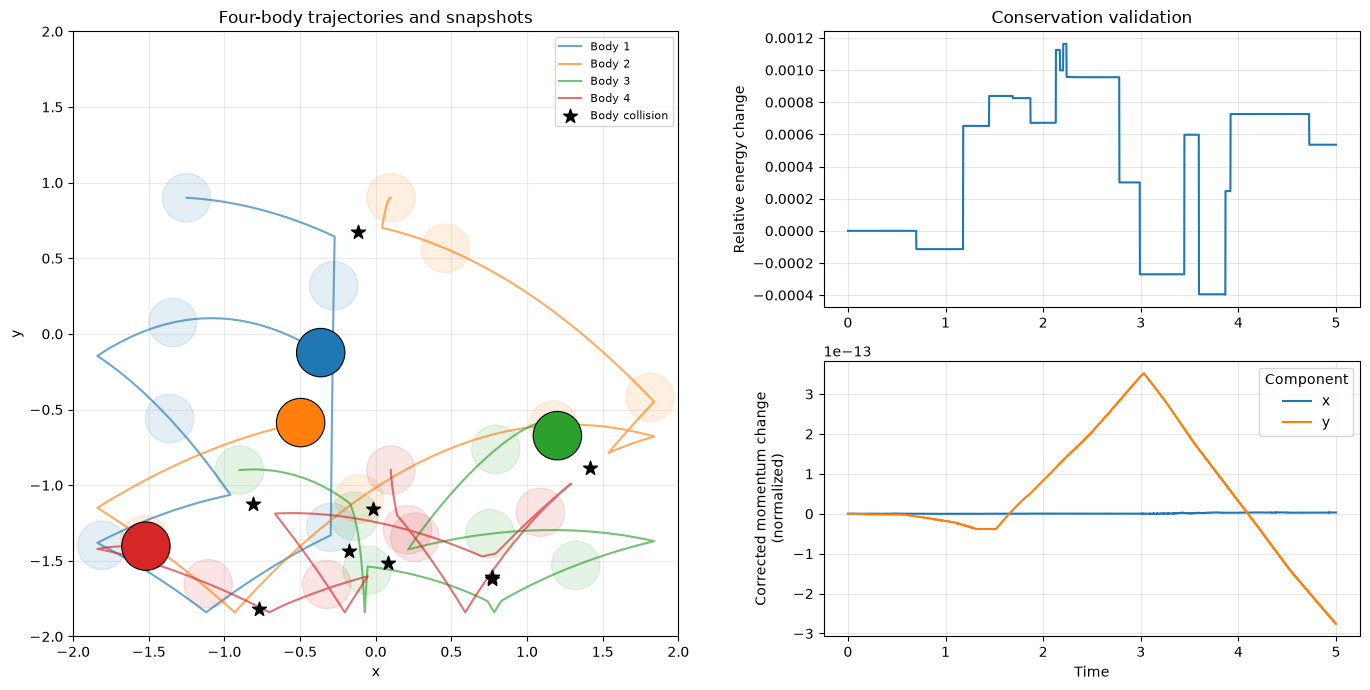

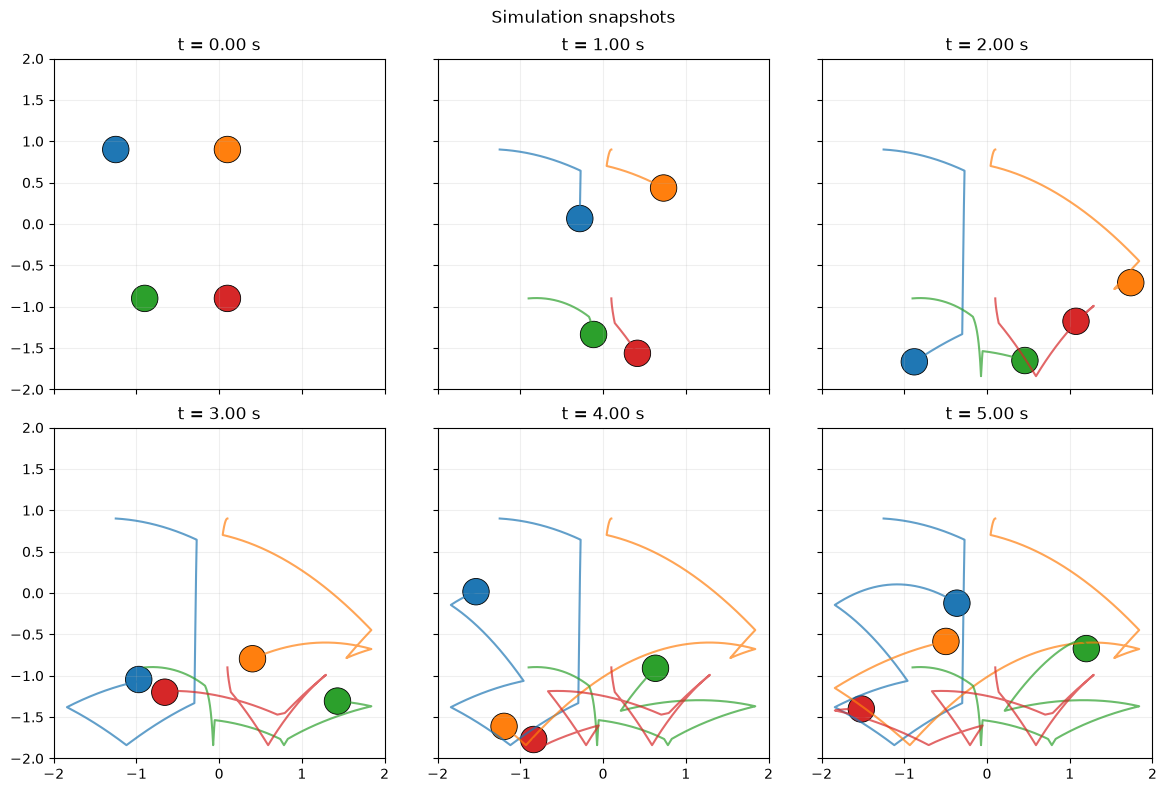

Recorded 9 body-body collision event(s).


In [3]:
# Elastic wall collisions
original_handle_collisions = world.handle_collisions
collision_points = []
wall_impulse_total = np.zeros(2)
gravity_impulse_total = np.zeros(2)
last_collision_time = {}
current_dt = 0.0

def handle_collisions_with_box():
    global current_dt

    # Record body-body contacts before the engine resolves their overlap.
    contacts = []
    for i, body1 in enumerate(world.bodies):
        for j, body2 in enumerate(world.bodies[i + 1:], start=i + 1):
            if np.linalg.norm(body2.r - body1.r) < body1.radius + body2.radius:
                contacts.append((i, j))

    original_handle_collisions()

    for i, j in contacts:
        key = (i, j)
        if world.time - last_collision_time.get(key, -1e9) > 0.05:
            collision_points.append((bodies[i].r + bodies[j].r) / 2)
            last_collision_time[key] = world.time

    # Reflect bodies elastically from the box boundaries.
    x_min, x_max, y_min, y_max = bounds
    for body in world.bodies:
        for axis, low, high in ((0, x_min, x_max), (1, y_min, y_max)):
            low += body.radius
            high -= body.radius
            old_velocity = body.v[axis]

            if body.r[axis] < low:
                body.r[axis] = low
                if body.v[axis] < 0:
                    body.v[axis] *= -1
            elif body.r[axis] > high:
                body.r[axis] = high
                if body.v[axis] > 0:
                    body.v[axis] *= -1

            wall_impulse_total[axis] += body.m * (body.v[axis] - old_velocity)

    gravity_impulse_total[:] += sum((body.m * gravity.g * current_dt for body in world.bodies), start=np.zeros(2))

world.handle_collisions = handle_collisions_with_box

# Run and record the trajectory
steps = int(duration / dt)
world.record_state()

initial_momentum = world.history[-1]["momentum"].copy()
momentum_scale = max(sum(body.m * np.linalg.norm(body.v) for body in bodies), 1.0)
initial_energy = world.history[-1]["total_energy"]
energy_scale = max(abs(initial_energy), 1.0)

corrected_momentum_history = [initial_momentum.copy()]

for _ in range(steps):
    current_dt = dt
    world.step(dt)
    momentum = world.history[-1]["momentum"]
    corrected_momentum_history.append(momentum - gravity_impulse_total - wall_impulse_total)

times = np.array([state["time"] for state in world.history])
positions = np.array([state["positions"] for state in world.history])
energies = np.array([state["total_energy"] for state in world.history])
corrected_momentum = np.array(corrected_momentum_history)
energy_drift = (energies - energies[0]) / energy_scale
momentum_drift = (corrected_momentum - corrected_momentum[0]) / momentum_scale

# Trajectory and Conservation check graphs
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
snapshot_indices = np.linspace(0, steps, 7, dtype=int)

fig = plt.figure(figsize=(14, 7))
gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 1])

ax = fig.add_subplot(gs[:, 0])
energy_ax = fig.add_subplot(gs[0, 1])
momentum_ax = fig.add_subplot(gs[1, 1], sharex=energy_ax)

# Trajectories, snapshots, and final body positions
for i, color in enumerate(colors):
    ax.plot(positions[:, i, 0], positions[:, i, 1], color=color, alpha=0.65,
            label=f"Body {i + 1}")
    for index in snapshot_indices[:-1]:
        ax.add_patch(plt.Circle(positions[index, i], radius, color=color, alpha=0.12))
    ax.add_patch(plt.Circle(
        positions[-1, i], radius, color=color, ec="black", lw=0.8, zorder=5
    ))

if collision_points:
    collision_points_array = np.asarray(collision_points)
    ax.scatter(collision_points_array[:, 0], collision_points_array[:, 1],
               marker="*", s=110, color="black", label="Body collision", zorder=6)

x_min, x_max, y_min, y_max = bounds
ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max), xlabel="x", ylabel="y",
       title="Four-body trajectories and snapshots")
ax.set_aspect("equal")
ax.grid(alpha=0.25)
ax.legend(loc="upper right", fontsize=8)

# Conservation diagnostics
energy_ax.plot(times, energy_drift)
energy_ax.set_ylabel("Relative energy change")
energy_ax.set_title("Conservation validation")
energy_ax.grid(alpha=0.3)

momentum_ax.plot(times, momentum_drift[:, 0], label="x")
momentum_ax.plot(times, momentum_drift[:, 1], label="y")
momentum_ax.set_xlabel("Time")
momentum_ax.set_ylabel("Corrected momentum change\n(normalized)")
momentum_ax.legend(title="Component")
momentum_ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

# Snapshot Graphs
sequence_indices = np.linspace(0, steps, 6, dtype=int)
fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)

for ax, index in zip(axes.flat, sequence_indices):
    for i, color in enumerate(colors):
        ax.plot(positions[:index + 1, i, 0], positions[:index + 1, i, 1], color=color, alpha=0.7)
        ax.add_patch(plt.Circle(positions[index, i], radius, color=color, ec="black", lw=0.6))
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("equal")
    ax.set_title(f"t = {times[index]:.2f} s")
    ax.grid(alpha=0.2)

fig.suptitle("Simulation snapshots")
plt.tight_layout()
plt.show()
print(f"Recorded {len(collision_points)} body-body collision event(s).")